# TDE 03 - Baseline do Projeto: Avaliação de Compra de Produto Bancário (Bank Marketing)

**Métrica principal de comparação:** F1-Score (classe positiva: cliente que contratou o depósito a prazo)

## 1. Contextualização e objetivo desta etapa

No **TDE 01** realizamos a Análise Exploratória de Dados (EDA) da base *Bank Marketing*, com cerca de 41,2 mil contatos de telemarketing de uma instituição financeira portuguesa. Cada observação representa **um contato com um cliente** e o alvo (`y`) indica se ele **subscreveu ou não um depósito a prazo**.

A EDA trouxe quatro achados que guiam as decisões deste notebook:

1. **Desbalanceamento:** apenas ~11,3% dos contatos resultam em conversão (`yes`). Por isso a acurácia sozinha engana e o F1-score é a métrica principal.
2. **Target leakage em `duration`:** a duração da chamada só é conhecida depois que a ligação acontece. Ela **não pode ser usada** em um modelo que pretende apoiar a decisão de *quem ligar*. Será removida do baseline.
3. **Sinal histórico forte:** `poutcome = success` tem a maior taxa de conversão.
4. **Sensibilidade macroeconômica:** variáveis como `euribor3m` se relacionam com a conversão.

**O que é um baseline?** É o ponto de partida: algoritmos vistos em sala, com **hiperparâmetros padrão, sem balanceamento de classes e sem ajuste fino**. Seus resultados servirão de referência para medir o ganho das otimizações da próxima etapa (balanceamento, tuning, explicabilidade).

**Algoritmos avaliados:** Regressão Logística, k-NN, Árvore de Decisão, Random Forest e Naive Bayes Gaussiano, além de um classificador "ingênuo" (`DummyClassifier`) como piso de comparação.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report,
    roc_curve, precision_recall_curve,
)

warnings.filterwarnings("ignore")

SEED = 42  # reprodutibilidade

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

## 2. Carregamento dos dados

Mesma fonte do TDE 01 (Google Drive via Colab). O código também funciona localmente, caso o arquivo esteja na mesma pasta do notebook.

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    caminho_arquivo = "/content/drive/MyDrive/bank-additional-full.csv"
except ImportError:
    caminho_arquivo = "bank-additional-full.csv"  # execução local

try:
    df_raw = pd.read_csv(caminho_arquivo, sep=";")
    print("✅ Dados carregados com sucesso!")
except FileNotFoundError:
    raise FileNotFoundError(
        f"Arquivo não encontrado em '{caminho_arquivo}'. Ajuste a variável `caminho_arquivo`."
    )

print(f"Dimensões: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
df_raw.head()

✅ Dados carregados com sucesso!
Dimensões: 41188 linhas x 21 colunas


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Preparação mínima dos dados

Apenas o **estritamente necessário** para que os algoritmos funcionem. Otimizações ficam para a próxima etapa.

| Decisão | Justificativa |
|---|---|
| Remover duplicatas | Identificadas no TDE 01. Se ficassem, a mesma linha poderia cair em treino e teste, inflando o desempenho. |
| Codificar `y` em 0/1 | Os algoritmos e as métricas exigem alvo numérico; `1` = contratou. |
| **Remover `duration`** | *Target leakage* (achado 2 da EDA): só é conhecida após a ligação. |
| `pdays = 999` → flag + 0 | O valor 999 significa "nunca contatado antes", não "999 dias". Mantê-lo distorceria algoritmos sensíveis a escala (Regressão Logística e k-NN). Criamos `contatado_antes` e zeramos `pdays` nesses casos. |
| Manter `unknown` como categoria | É informação (o cliente não declarou o dado); não faremos imputação no baseline. |

In [ ]:
df = df_raw.copy()

# 1) Duplicatas
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicatas removidas: {n_dup} | Linhas restantes: {len(df)}")

# 2) Alvo binário
df["y"] = (df["y"] == "yes").astype(int)

# 3) Leakage: duration fora do conjunto de features
df_com_duration = df.copy()          # guardado só para a análise complementar da seção 9
df = df.drop(columns=["duration"])

# 4) pdays = 999 significa "nunca contatado"
df["contatado_antes"] = (df["pdays"] != 999).astype(int)
df.loc[df["pdays"] == 999, "pdays"] = 0

X = df.drop(columns=["y"])
y = df["y"]

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"\nFeatures categóricas ({len(cat_cols)}): {cat_cols}")
print(f"Features numéricas   ({len(num_cols)}): {num_cols}")
print(f"\nProporção da classe positiva: {y.mean()*100:.2f}%")

Duplicatas removidas: 12 | Linhas restantes: 41176

Features categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Features numéricas   (10): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contatado_antes']

Proporção da classe positiva: 11.27%


## 4. Divisão treino/teste

Divisão **estratificada 80/20**: preserva os ~11% de positivos nos dois conjuntos. O conjunto de teste fica "trancado" até a avaliação final; as decisões de comparação interna usam validação cruzada apenas no treino.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Treino: {X_train.shape[0]} amostras | positivos: {y_train.mean()*100:.2f}%")
print(f"Teste : {X_test.shape[0]} amostras | positivos: {y_test.mean()*100:.2f}%")

Treino: 32940 amostras | positivos: 11.27%
Teste : 8236 amostras | positivos: 11.27%


## 5. Definição dos modelos baseline

O pré-processamento está **dentro de um `Pipeline`**, ajustado só com os dados de treino de cada etapa. Isso evita vazamento de informação do teste (ou do fold de validação) para o treino.

- **Numéricas:** `StandardScaler` (necessário para k-NN e Regressão Logística; inofensivo para os demais).
- **Categóricas:** `OneHotEncoder` (`handle_unknown="ignore"`).
- **Hiperparâmetros:** todos nos valores padrão do scikit-learn (apenas `random_state` fixado e `max_iter` ampliado na Regressão Logística para garantir convergência). **Sem `class_weight` e sem reamostragem.**

In [ ]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

modelos = {
    "Dummy (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística":        LogisticRegression(max_iter=1000, random_state=SEED),
    "k-NN (k=5)":                 KNeighborsClassifier(),
    "Árvore de Decisão":          DecisionTreeClassifier(random_state=SEED),
    "Random Forest":              RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "Naive Bayes Gaussiano":      GaussianNB(),
}

def make_pipeline(modelo):
    pre = make_preprocessor()
    # GaussianNB e demais não aceitam matriz esparsa em alguns casos -> forçamos densa
    pre.set_params(sparse_threshold=0)
    return Pipeline([("pre", pre), ("clf", modelo)])

pipelines = {nome: make_pipeline(m) for nome, m in modelos.items()}
print("Modelos definidos:", list(pipelines))

Modelos definidos: ['Dummy (classe majoritária)', 'Regressão Logística', 'k-NN (k=5)', 'Árvore de Decisão', 'Random Forest', 'Naive Bayes Gaussiano']


## 6. Validação cruzada estratificada (5 folds) no conjunto de treino

A validação cruzada mostra **o quanto o desempenho varia entre diferentes recortes dos dados**. Um desvio-padrão alto indica um modelo instável. Reportamos média ± desvio-padrão.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

linhas_cv = []
for nome, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    linha = {"Modelo": nome}
    for m in scoring:
        v = res[f"test_{m}"]
        linha[m] = f"{v.mean():.3f} ± {v.std():.3f}"
    linhas_cv.append(linha)
    print(f"✔ {nome}")

df_cv = pd.DataFrame(linhas_cv).set_index("Modelo")
df_cv

✔ Dummy (classe majoritária)


✔ Regressão Logística


✔ k-NN (k=5)


✔ Árvore de Decisão


✔ Random Forest


✔ Naive Bayes Gaussiano


,accuracy,precision,recall,f1,roc_auc,pr_auc
Modelo,,,,,,
Dummy (classe majoritária),0.887 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.113 ± 0.000
Regressão Logística,0.900 ± 0.001,0.666 ± 0.024,0.230 ± 0.005,0.342 ± 0.005,0.790 ± 0.007,0.451 ± 0.014
k-NN (k=5),0.892 ± 0.002,0.534 ± 0.019,0.296 ± 0.012,0.381 ± 0.012,0.725 ± 0.008,0.323 ± 0.008
Árvore de Decisão,0.841 ± 0.003,0.311 ± 0.007,0.338 ± 0.011,0.324 ± 0.006,0.624 ± 0.004,0.182 ± 0.003
Random Forest,0.893 ± 0.001,0.545 ± 0.005,0.284 ± 0.011,0.373 ± 0.009,0.774 ± 0.006,0.407 ± 0.005
Naive Bayes Gaussiano,0.819 ± 0.007,0.325 ± 0.013,0.559 ± 0.021,0.411 ± 0.012,0.766 ± 0.011,0.350 ± 0.012


## 7. Avaliação final no conjunto de teste

Cada modelo é treinado com **todo** o conjunto de treino e avaliado uma única vez no teste, com o limiar de decisão padrão (0,5).

**Métricas e como lê-las neste problema:**

- **Acurácia:** proporção de acertos. Enganosa aqui: prever "não" para todos já daria ~89%.
- **Precisão:** dos clientes que o modelo apontou como compradores, quantos realmente compraram (custo de ligar à toa).
- **Recall (revocação):** dos compradores reais, quantos o modelo encontrou (oportunidades perdidas).
- **F1-score:** média harmônica de precisão e recall. **É a métrica oficial do projeto.**
- **ROC-AUC:** capacidade de ranquear positivos acima de negativos, independente do limiar.
- **PR-AUC (Average Precision):** análoga à anterior, mas mais informativa quando a classe positiva é rara.

In [ ]:
resultados = []
preds = {}      # classes previstas
probas = {}     # probabilidade da classe positiva
treinados = {}

for nome, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    treinados[nome] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    preds[nome], probas[nome] = y_pred, y_proba

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
        "F1 (treino)": f1_score(y_train, pipe.predict(X_train)),
    })

df_res = pd.DataFrame(resultados).set_index("Modelo").sort_values("F1", ascending=False)
df_res.style.format("{:.3f}").background_gradient(cmap="Greens", subset=["F1", "ROC-AUC", "PR-AUC"])

,Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC,F1 (treino)
Modelo,,,,,,,
Naive Bayes Gaussiano,0.823,0.336,0.583,0.426,0.776,0.360,0.411
k-NN (k=5),0.895,0.560,0.300,0.390,0.740,0.345,0.503
Random Forest,0.893,0.545,0.281,0.371,0.778,0.423,0.978
Árvore de Decisão,0.842,0.313,0.339,0.326,0.626,0.183,0.978
Regressão Logística,0.898,0.647,0.211,0.318,0.800,0.454,0.346
Dummy (classe majoritária),0.887,0.000,0.000,0.000,0.500,0.113,0.000


### 7.1 Comparação visual do F1-score e demais métricas

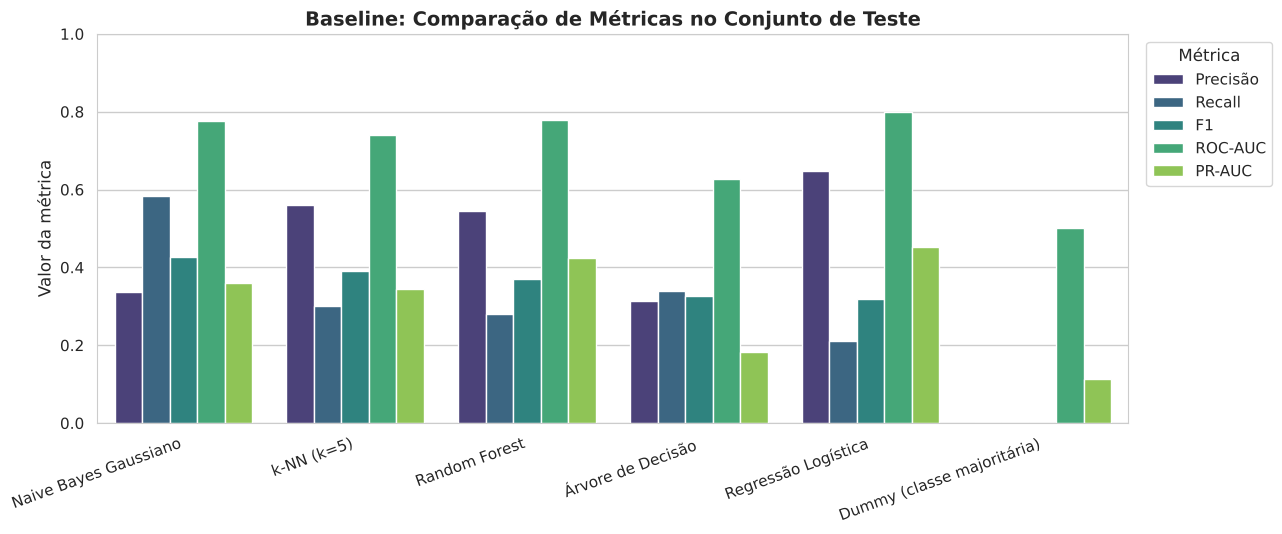

In [ ]:
metricas_plot = ["Precisão", "Recall", "F1", "ROC-AUC", "PR-AUC"]
df_plot = df_res[metricas_plot].reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")

plt.figure(figsize=(13, 5.5))
sns.barplot(data=df_plot, x="Modelo", y="Valor", hue="Métrica", palette="viridis")
plt.title("Baseline: Comparação de Métricas no Conjunto de Teste", fontsize=14, fontweight="bold")
plt.xlabel("")
plt.ylabel("Valor da métrica")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(title="Métrica", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 7.2 Matrizes de confusão

Mostram **que tipo de erro** cada modelo comete: falsos negativos (compradores não detectados) ou falsos positivos (ligações desperdiçadas).

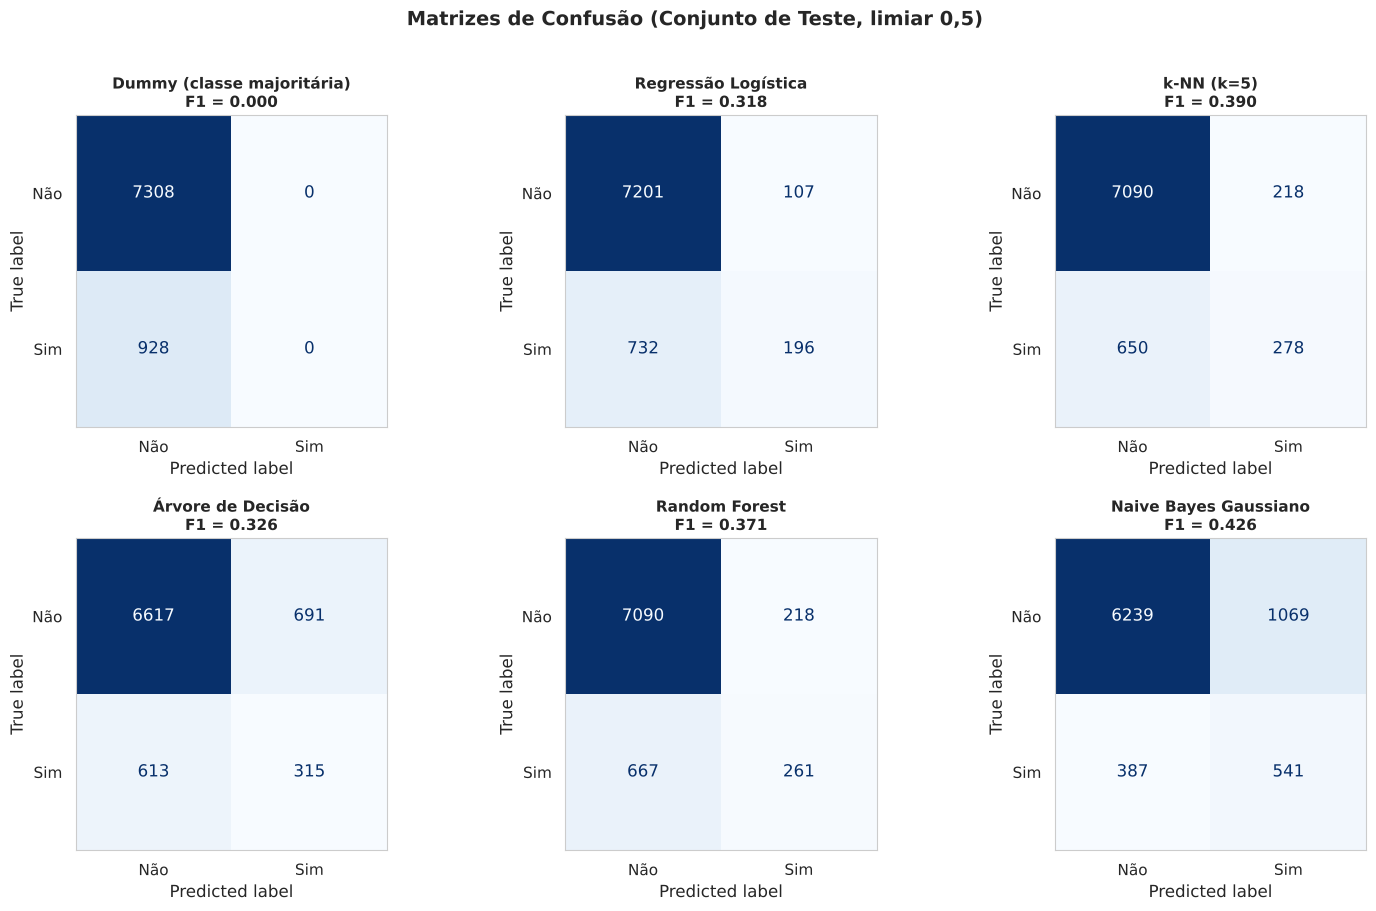

In [ ]:
nomes = list(pipelines)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, nome in zip(axes.ravel(), nomes):
    cm = confusion_matrix(y_test, preds[nome])
    ConfusionMatrixDisplay(cm, display_labels=["Não", "Sim"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{nome}\nF1 = {f1_score(y_test, preds[nome]):.3f}", fontsize=11, fontweight="bold")
    ax.grid(False)
plt.suptitle("Matrizes de Confusão (Conjunto de Teste, limiar 0,5)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### 7.3 Curvas ROC e Precisão-Recall

A curva PR é a mais adequada para classes desbalanceadas; a linha tracejada nela representa o desempenho de um classificador aleatório (proporção de positivos).

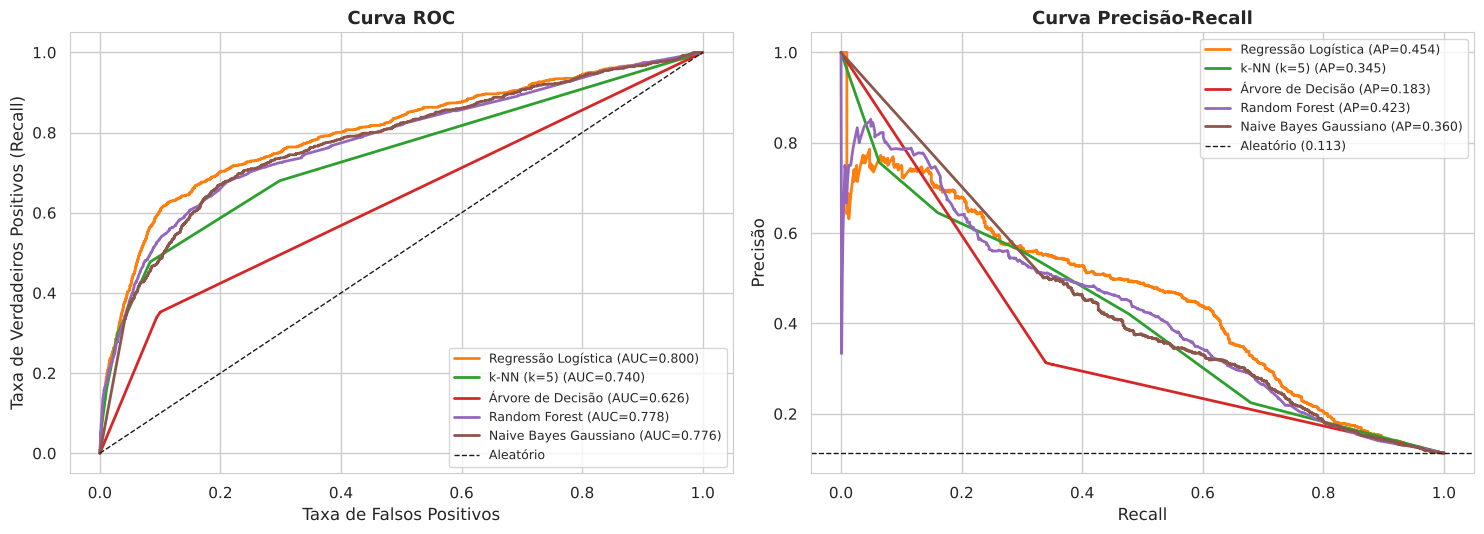

In [ ]:
cores = dict(zip(nomes, sns.color_palette("tab10", len(nomes))))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for nome in nomes:
    if nome.startswith("Dummy"):
        continue
    fpr, tpr, _ = roc_curve(y_test, probas[nome])
    axes[0].plot(fpr, tpr, color=cores[nome], lw=2, label=f"{nome} (AUC={roc_auc_score(y_test, probas[nome]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, probas[nome])
    axes[1].plot(rec, prec, color=cores[nome], lw=2, label=f"{nome} (AP={average_precision_score(y_test, probas[nome]):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Aleatório")
axes[0].set_title("Curva ROC", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Taxa de Falsos Positivos")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Aleatório ({y_test.mean():.3f})")
axes[1].set_title("Curva Precisão-Recall", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

### 7.4 Relatório de classificação do melhor modelo (por F1)

In [ ]:
melhor = df_res.index[0]
print(f"Melhor baseline por F1 no teste: {melhor}\n")
print(classification_report(y_test, preds[melhor], target_names=["Não contratou", "Contratou"], digits=3))

Melhor baseline por F1 no teste: Naive Bayes Gaussiano

               precision    recall  f1-score   support

Não contratou      0.942     0.854     0.896      7308
    Contratou      0.336     0.583     0.426       928

     accuracy                          0.823      8236
    macro avg      0.639     0.718     0.661      8236
 weighted avg      0.873     0.823     0.843      8236



## 8. Diagnóstico de sobreajuste (overfitting)

Comparamos o F1 no **treino** com o F1 no **teste**. Uma diferença grande indica que o modelo memoriza os dados de treino em vez de generalizar.

,F1 (treino),F1 (teste),Diferença
Modelo,,,
Naive Bayes Gaussiano,0.411,0.426,-0.015
k-NN (k=5),0.503,0.390,0.112
Random Forest,0.978,0.371,0.607
Árvore de Decisão,0.978,0.326,0.652
Regressão Logística,0.346,0.318,0.027
Dummy (classe majoritária),0.000,0.000,0.000


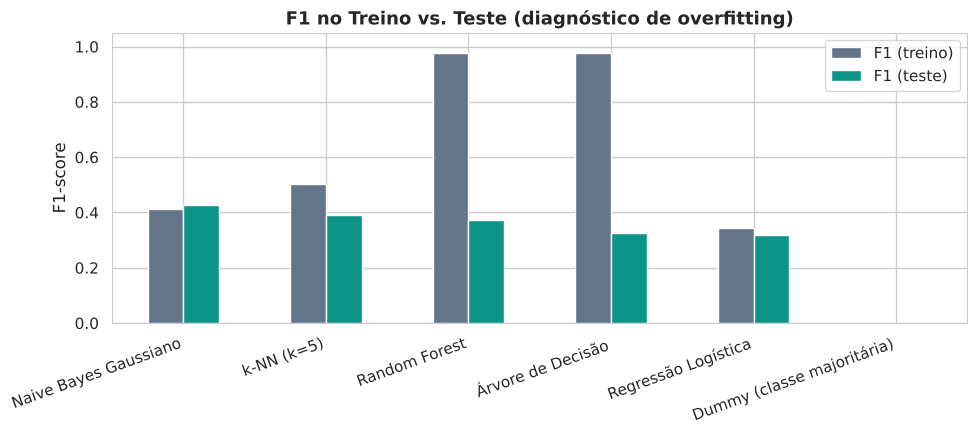

In [ ]:
df_over = df_res[["F1 (treino)", "F1"]].rename(columns={"F1": "F1 (teste)"}).copy()
df_over["Diferença"] = df_over["F1 (treino)"] - df_over["F1 (teste)"]
display(df_over.style.format("{:.3f}").background_gradient(cmap="Reds", subset=["Diferença"]))

df_over[["F1 (treino)", "F1 (teste)"]].plot(kind="bar", figsize=(10, 4.5), color=["#64748b", "#0d9488"])
plt.title("F1 no Treino vs. Teste (diagnóstico de overfitting)", fontsize=13, fontweight="bold")
plt.ylabel("F1-score")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

## 9. Análise complementar: o efeito do *target leakage* de `duration`

Na EDA afirmamos que `duration` não deve ser usada. Aqui **quantificamos** o que ela "entregaria" se fosse (indevidamente) incluída, usando o mesmo Random Forest baseline. Este resultado **não é o baseline oficial**; serve apenas para justificar a decisão de remoção e dimensionar o quanto o desempenho seria artificialmente inflado.

In [ ]:
dfl = df_com_duration.copy()
dfl["contatado_antes"] = (dfl["pdays"] != 999).astype(int)
dfl.loc[dfl["pdays"] == 999, "pdays"] = 0

Xl, yl = dfl.drop(columns=["y"]), dfl["y"]
num_cols_l = Xl.select_dtypes(include=[np.number]).columns.tolist()

Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, yl, test_size=0.20, stratify=yl, random_state=SEED)

pre_l = ColumnTransformer([
    ("num", StandardScaler(), num_cols_l),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)
rf_l = Pipeline([("pre", pre_l), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]).fit(Xl_tr, yl_tr)

f1_com = f1_score(yl_te, rf_l.predict(Xl_te))
auc_com = roc_auc_score(yl_te, rf_l.predict_proba(Xl_te)[:, 1])
f1_sem = df_res.loc["Random Forest", "F1"]
auc_sem = df_res.loc["Random Forest", "ROC-AUC"]

comp = pd.DataFrame({
    "F1": [f1_sem, f1_com],
    "ROC-AUC": [auc_sem, auc_com],
}, index=["Random Forest SEM duration (baseline oficial)", "Random Forest COM duration (vazamento)"])
display(comp.style.format("{:.3f}"))
print(f"Ganho aparente de F1 por usar duration: +{(f1_com - f1_sem):.3f}")

,F1,ROC-AUC
Random Forest SEM duration (baseline oficial),0.371,0.778
Random Forest COM duration (vazamento),0.559,0.944


Ganho aparente de F1 por usar duration: +0.188


## 10. Resumo automático dos resultados

In [ ]:
print("=" * 60)
print("RESUMO DO BASELINE (conjunto de teste, limiar 0,5)")
print("=" * 60)
print(df_res[["Acurácia", "Precisão", "Recall", "F1", "ROC-AUC", "PR-AUC"]].round(3).to_string())

melhor_f1 = df_res["F1"].idxmax()
melhor_auc = df_res["ROC-AUC"].idxmax()
melhor_rec = df_res["Recall"].idxmax()
print(f"\n→ Maior F1      : {melhor_f1} ({df_res.loc[melhor_f1, 'F1']:.3f})")
print(f"→ Maior ROC-AUC : {melhor_auc} ({df_res.loc[melhor_auc, 'ROC-AUC']:.3f})")
print(f"→ Maior Recall  : {melhor_rec} ({df_res.loc[melhor_rec, 'Recall']:.3f})")
print(f"→ Acurácia do Dummy: {df_res.loc['Dummy (classe majoritária)', 'Acurácia']:.3f} "
      f"(F1 = {df_res.loc['Dummy (classe majoritária)', 'F1']:.3f})")

RESUMO DO BASELINE (conjunto de teste, limiar 0,5)
                            Acurácia  Precisão  Recall     F1  ROC-AUC  PR-AUC
Modelo                                                                        
Naive Bayes Gaussiano          0.823     0.336   0.583  0.426    0.776   0.360
k-NN (k=5)                     0.895     0.560   0.300  0.390    0.740   0.345
Random Forest                  0.893     0.545   0.281  0.371    0.778   0.423
Árvore de Decisão              0.842     0.313   0.339  0.326    0.626   0.183
Regressão Logística            0.898     0.647   0.211  0.318    0.800   0.454
Dummy (classe majoritária)     0.887     0.000   0.000  0.000    0.500   0.113

→ Maior F1      : Naive Bayes Gaussiano (0.426)
→ Maior ROC-AUC : Regressão Logística (0.800)
→ Maior Recall  : Naive Bayes Gaussiano (0.583)
→ Acurácia do Dummy: 0.887 (F1 = 0.000)


## 11. Discussão dos resultados

> Os valores abaixo referem-se à execução com `SEED = 42` (divisão 80/20 estratificada, 8.236 amostras de teste, 928 positivos). Em outra semente os números mudam ligeiramente.

**1. A acurácia engana.** O `DummyClassifier`, que sempre responde "não", obtém **acurácia de 0,887 e F1 = 0**: não encontra nenhum comprador. Regressão Logística (0,898), k-NN (0,895) e Random Forest (0,893) superam esse piso por menos de 1,2 ponto percentual em acurácia, enquanto o Naive Bayes tem acurácia *menor* (0,823) e, ainda assim, o **maior F1 (0,426)**. Isso confirma o alerta da EDA sobre o desbalanceamento e justifica o F1 como métrica principal.

**2. Trade-off entre precisão e recall.** Sem tratamento do desbalanceamento, a maioria dos modelos é conservadora. A Regressão Logística tem a maior precisão (0,647), mas o menor recall entre os modelos úteis (0,211): acerta quando aponta um comprador, porém deixa escapar ~79% deles. O Naive Bayes faz o oposto: recall de 0,583 (encontra mais da metade dos compradores) com precisão de apenas 0,336, ou seja, cerca de 2 em cada 3 ligações indicadas seriam desperdiçadas. Para o negócio, a escolha entre esses perfis depende do custo de uma ligação contra o ganho de uma conversão.

**3. Comparação entre algoritmos (F1 no teste; média na validação cruzada entre parênteses).**
- *Naive Bayes Gaussiano:* F1 **0,426** (0,411 ± 0,012). Vence em F1 por causa do recall alto, mas seu ROC-AUC (0,776) e PR-AUC (0,360) são inferiores aos da Regressão Logística e do Random Forest. Em outras palavras, ele "ganha" por classificar mais contatos como positivos no limiar 0,5, e não por ordenar melhor os clientes.
- *k-NN (k=5):* F1 0,390 (0,381 ± 0,012). Bom equilíbrio entre precisão (0,560) e recall (0,300), mas ROC-AUC mais baixo (0,740).
- *Random Forest:* F1 0,371 (0,373 ± 0,009), com os melhores resultados de ranqueamento depois da Regressão Logística (ROC-AUC 0,778; PR-AUC 0,423).
- *Árvore de Decisão:* F1 0,326 (0,324 ± 0,006) e ROC-AUC de apenas 0,626, o pior entre os modelos úteis. Uma árvore sem poda produz probabilidades quase binárias, o que prejudica as métricas baseadas em ranking.
- *Regressão Logística:* F1 apenas 0,318 (0,342 ± 0,005), mas **melhor ROC-AUC (0,800) e PR-AUC (0,454)**. Há bom sinal nas variáveis; o F1 baixo vem principalmente do limiar fixo de 0,5 combinado ao desbalanceamento.

**4. Divergência entre F1 e métricas de ranqueamento.** O modelo de maior F1 (Naive Bayes) não é o de maior ROC-AUC/PR-AUC (Regressão Logística). Como o F1 depende do limiar de decisão e as AUCs não, é provável que a ordem dos modelos mude quando o limiar for otimizado na próxima etapa. Por isso o baseline deve ser lido como "desempenho com limiar 0,5", e não como o teto de cada algoritmo.

**5. Sobreajuste.** A seção 8 mostra dois casos extremos: **Árvore de Decisão (F1 treino 0,978 contra 0,326 no teste) e Random Forest (0,978 contra 0,371)**. Ambos memorizam o treino. O k-NN também apresenta diferença relevante (0,503 contra 0,390). Já Regressão Logística (0,346 contra 0,318) e Naive Bayes (0,411 contra 0,426) generalizam de forma consistente, porém por serem modelos simples, com viés alto. Restringir profundidade, `min_samples_leaf` e outros hiperparâmetros nos modelos de árvore é uma frente clara de melhoria.

**6. Estabilidade.** Os desvios-padrão do F1 na validação cruzada são pequenos (de 0,005 a 0,012), e a média do F1 na validação cruzada fica próxima do F1 no teste para todos os modelos. Isso indica que o resultado não depende de uma divisão específica dos dados.

**7. Confirmação do *leakage* de `duration`.** Incluir `duration` no Random Forest eleva o F1 de **0,371 para 0,559 (+0,188)** e o ROC-AUC de **0,778 para 0,944**. Esse ganho é artificial, pois a duração só é conhecida após a ligação. Logo, a remoção feita no baseline é a decisão correta e os números oficiais representam o desempenho **realista** de um modelo aplicável antes do contato.

**8. Há sinal, mas o desempenho ainda é modesto.** ROC-AUC próximo de 0,80 na Regressão Logística mostra que as variáveis (histórico de campanha, indicadores macroeconômicos, perfil do cliente) carregam informação, em linha com a EDA. Mesmo assim, o melhor F1 não chega a 0,43, o que deixa bastante espaço para o balanceamento, o ajuste de limiar e o tuning.

## 12. Conclusão e próximos passos

**Baseline definido:** o **Naive Bayes Gaussiano, com F1 = 0,426** no teste (precisão 0,336; recall 0,583; ROC-AUC 0,776), é a referência numérica que as soluções da próxima etapa precisam superar. Como referência complementar de ranqueamento, a Regressão Logística tem o melhor ROC-AUC (0,800) e PR-AUC (0,454).

**Limitações deste baseline:**
- Hiperparâmetros padrão e limiar fixo em 0,5.
- Sem tratamento do desbalanceamento.
- Divisão treino/teste única (mitigada pela validação cruzada no treino).
- Categorias `unknown` tratadas como categoria própria, sem imputação.
- Os dados cobrem um período específico (2008 a 2010), com forte componente macroeconômico, o que limita a generalização para outros contextos.

**Próximos passos (TDE seguinte):**
1. **Balanceamento:** `class_weight="balanced"`, *undersampling*, *oversampling* (SMOTE), sempre aplicados **apenas dentro do treino/folds**.
2. **Otimização de limiar** de decisão para maximizar o F1 (curva Precisão-Recall).
3. **Ajuste de hiperparâmetros** (`GridSearchCV`/`RandomizedSearchCV`) com F1 como métrica de seleção, em especial para Árvore e Random Forest, para reduzir o sobreajuste.
4. **Engenharia de atributos:** tratamento de `unknown`, agrupamento de categorias raras, interações entre variáveis macroeconômicas.
5. **Explicabilidade** (importância de atributos, SHAP) para entender quais variáveis sustentam as decisões e onde o modelo falha.